# 储氢材料的反向工程：从氢化物到母体合金 (Forward-Backward Design)
本笔记本旨在加载现有的 908 个金属氢化物，通过 Pymatgen 智能剥离其中的氢 (H) 元素，逆向还原出它们吸氢前的**母体合金最简化学式**。并针对“同一种合金存在多种吸氢相”的情况进行去重和信息聚合，为下一阶段的“纯合金预测验证模型”准备黄金数据集。

In [1]:
import pandas as pd
import numpy as np
import warnings
from pymatgen.core import Composition

warnings.filterwarnings("ignore")

print("==========================================")
print(" 阶段 1：加载原始含氢数据并定义物理剥离函数")
print("==========================================")

# 1. 载入原始 908 个氢化物数据
try:
    df_raw = pd.read_csv("final_hydrides_features.csv")
    print(f"🚗 成功加载原始含氢数据：{len(df_raw)} 条样本")
except FileNotFoundError:
    print("❌ 找不到 final_hydrides_features.csv，检查路径是否正确。")

# 2. 定义剥离氢原子获取母体合金的函数
def extract_parent_alloy(formula):
    """
    读取化学式（如 Mg2FeH6），剥离 H 元素，
    返回最简比母体合金（Reduced Formula, 如 Mg2Fe）。
    """
    try:
        comp = Composition(formula)
        # 把 H 的数量设为 0 或者直接在新字典里过滤掉 H
        alloy_dict = {el.symbol: amt for el, amt in comp.items() if el.symbol != 'H'}
        if not alloy_dict:
            return None # 如果是纯氢 H2、H 等极端情况，剥离后为空
        parent_comp = Composition(alloy_dict)
        # .reduced_formula 会自动将晶胞化简为最简整数比 (例如 La2Ni10 -> LaNi5)
        return parent_comp.reduced_formula 
    except Exception as e:
        return None

# 3. 执行物理剥离
df_raw['Parent_Alloy'] = df_raw['Formula'].apply(extract_parent_alloy)

# 清理无效行 (极小概率存在无母体合金的纯氢态)
df_clean = df_raw.dropna(subset=['Parent_Alloy']).copy()
print(f"✅ 成功完成所有化学式的 H 原子剥离，有效样本量：{len(df_clean)}")

 阶段 1：加载原始含氢数据并定义物理剥离函数
🚗 成功加载原始含氢数据：908 条样本
✅ 成功完成所有化学式的 H 原子剥离，有效样本量：908


In [2]:
print("\n==========================================")
print(" 阶段 2：计算储氢容量并处理『一对多』的同源坍缩")
print("==========================================")

# 很多合金在不同温度压力下吸氢量不同（比如 V 可以形成 V2H, VH, VH2）
# 我们需要评估每个氢化物的氢质量分数 (W_H2)，
# 在聚合时，我们提取该母体合金所能达到的【最大理论储氢容量 (Max W_H2)】作为上限靶向！

def get_w_h2(formula):
    try:
        comp = Composition(formula)
        mass_h = sum(ni * 1.008 for el, ni in comp.items() if el.symbol == 'H')
        return mass_h / comp.weight if comp.weight > 0 else 0
    except:
        return 0

df_clean['Hydrogen_Mass_Fraction'] = df_clean['Formula'].apply(get_w_h2)

# 按 'Parent_Alloy' 分组，对于每组合金，找到 'Hydrogen_Mass_Fraction' 最大的一行索引
idx_max_h2 = df_clean.groupby('Parent_Alloy')['Hydrogen_Mass_Fraction'].idxmax()
df_alloy = df_clean.loc[idx_max_h2].reset_index(drop=True)

# 确保目标函数 'Formation Energy (eV/atom)' 正确且保留
target_col = 'Formation Energy (eV/atom)'

print(f"🛡️ 同源去重与坍缩完成！")
print(f"从 {len(df_clean)} 个不同吸附相的氢化物中，提炼出了 {len(df_alloy)} 个绝对独立的【母体储氢合金】。")

# 预览前10条合金提炼结果
display_cols = ['Parent_Alloy', 'Formula', target_col, 'Hydrogen_Mass_Fraction']
display(df_alloy[display_cols].head(10).style.background_gradient(cmap='Blues', subset=['Hydrogen_Mass_Fraction']))


 阶段 2：计算储氢容量并处理『一对多』的同源坍缩
🛡️ 同源去重与坍缩完成！
从 908 个不同吸附相的氢化物中，提炼出了 498 个绝对独立的【母体储氢合金】。


,Parent_Alloy,Formula,Formation Energy (eV/atom),Hydrogen_Mass_Fraction
0,Ag,AgH,0.120898,0.009258
1,Al,AlH12,0.100714,0.309544
2,AlB3,Al(BH4)3,-0.103533,0.169152
3,AlFe3,AlFe3H,-0.205005,0.005155
4,As,AsH3,0.726922,0.038796
5,B,BH3,-0.044936,0.218579
6,Ba,BaH2,-0.578970,0.014468
7,Ba19Na29Li13,Ba38Na58Li26H,0.002417,0.000150
8,Ba2Al,Ba2AlH7,-0.530189,0.022858
9,Ba2Cu,Ba2CuH6,-0.411739,0.017569


In [3]:
print("\n==========================================")
print(" 阶段 3：构建基准数据集并保存")
print("==========================================")

# 只保留我们在新一轮机器学习里必须的核心骨架
# Parent_Alloy: 作为新的 X 去生成 Magpie
# Formation Energy (eV/atom): 作为原始标签参考
# Hydrogen_Mass_Fraction: 作为另一个强靶向目标

final_alloy_df = df_alloy[['Parent_Alloy', 'Formula', target_col, 'Hydrogen_Mass_Fraction', 'Material ID', 'Num Elements']].copy()

# ---> 新增规则：按母体母金的元数从少到多排序
final_alloy_df['Alloy_Num_Elements'] = final_alloy_df['Parent_Alloy'].apply(lambda x: len(Composition(x).elements))
final_alloy_df = final_alloy_df.sort_values(by=['Alloy_Num_Elements', 'Hydrogen_Mass_Fraction'], ascending=[True, False]).reset_index(drop=True)

# 重命名一下更贴切的字段名
final_alloy_df.rename(columns={
    'Parent_Alloy': '母体合金',
    'Alloy_Num_Elements': '元数',
    'Formula': '原最大储氢相',
    'Hydrogen_Mass_Fraction': '理论氢质量分数(W_H2)',
    target_col: '完全态生成能(eV/atom)'
}, inplace=True)

# 整理好列的显示顺序
col_order = ['母体合金', '元数', '原最大储氢相', '理论氢质量分数(W_H2)', '完全态生成能(eV/atom)', 'Material ID']
final_alloy_df = final_alloy_df[col_order]

import os
# 保存至该笔记本所在的同一本地相对路径
save_path = os.path.join(os.getcwd(), "parent_alloys_data.csv")
final_alloy_df.to_csv(save_path, index=False, encoding='utf-8-sig')

print(f"💾 母体合金黄金数据集已按元数(由低到高)排序，并成功保存至本地: {save_path}")

print("🏆 预览核心规整后的前 15 条纯合金数据：")
display(final_alloy_df.head(15).style.background_gradient(cmap='Blues', subset=['理论氢质量分数(W_H2)']))


 阶段 3：构建基准数据集并保存
💾 母体合金黄金数据集已按元数(由低到高)排序，并成功保存至本地: workspace\parent_alloys_data.csv
🏆 预览核心规整后的前 15 条纯合金数据：


,母体合金,元数,原最大储氢相,理论氢质量分数(W_H2),完全态生成能(eV/atom),Material ID
0,Al,1,AlH12,0.309544,0.100714,mp-1214891
1,Si,1,SiH8,0.223077,-0.002998,mp-972825
2,B,1,BH3,0.218579,-0.044936,mp-634117
3,Be,1,BeH2,0.182806,-0.164871,mp-768203
4,Li,1,LiH,0.126809,-0.489362,mp-23703
5,La,1,LaH20,0.126741,0.122634,mp-2647067
6,Mg,1,MgH3,0.110652,0.207381,mp-1185872
7,Zn,1,ZnH6,0.084639,0.182377,mp-1207466
8,K,1,KH3,0.071791,0.960021,mp-1184938
9,Ca,1,CaH3,0.070159,-0.195466,mp-1183578



 阶段 4：生成组成元素周期表频次热图 (Periodic Table Heatmap)


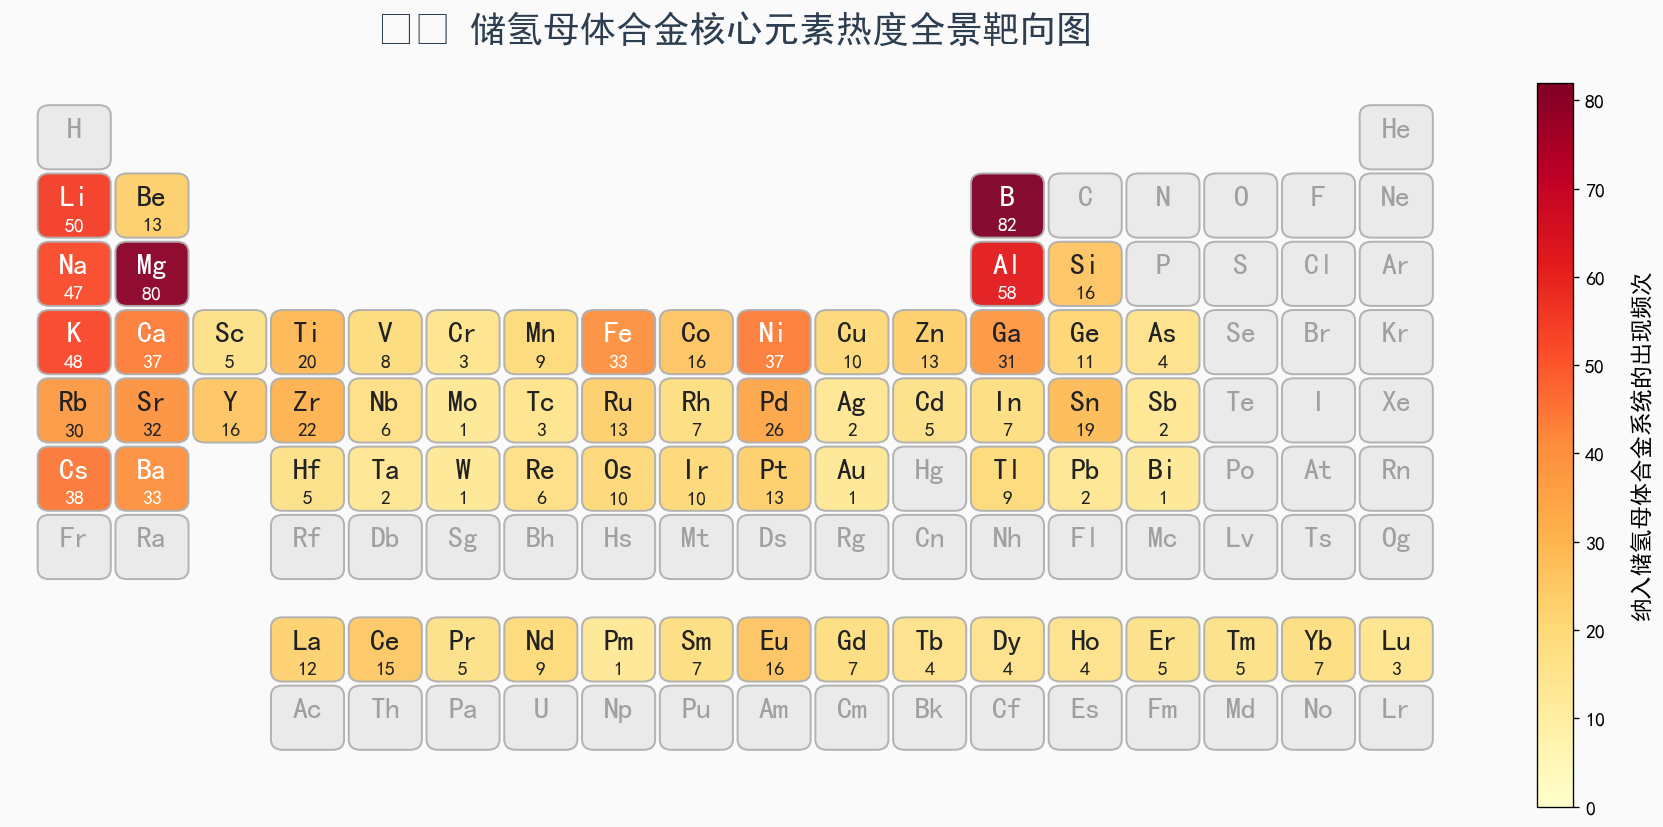


📊 驱动储氢合金的 Top 8 指标元素：
   No.1 核心主材：B 元素 (共出现在 82 种独立母体合金中)
   No.2 核心主材：Mg 元素 (共出现在 80 种独立母体合金中)
   No.3 核心主材：Al 元素 (共出现在 58 种独立母体合金中)
   No.4 核心主材：Li 元素 (共出现在 50 种独立母体合金中)
   No.5 核心主材：K 元素 (共出现在 48 种独立母体合金中)
   No.6 核心主材：Na 元素 (共出现在 47 种独立母体合金中)
   No.7 核心主材：Cs 元素 (共出现在 38 种独立母体合金中)
   No.8 核心主材：Ca 元素 (共出现在 37 种独立母体合金中)


In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.colors as mcolors
from pymatgen.core import Element

# 解决标题变方框乱码问题
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

print("\n==========================================")
print(" 阶段 4：生成组成元素周期表频次热图 (Periodic Table Heatmap)")
print("==========================================")

# 1. 统计每种元素在所有母体合金中出现的频次 (纯合金统计)
element_counts = {}
for formula in final_alloy_df['母体合金']:
    try:
        comp = Composition(formula)
        for el in comp.elements:
            sym = el.symbol
            element_counts[sym] = element_counts.get(sym, 0) + 1
    except:
        continue

# 2. 绘制高度自定义的周期表热图 (大小调整缩放，防撑满屏幕)
fig, ax = plt.subplots(figsize=(14, 7), dpi=120, facecolor='#FAFAFA')
ax.set_facecolor('#FAFAFA')

# 计算热图的颜色映射范围
max_val = max(element_counts.values()) if element_counts else 1
cmap = plt.cm.get_cmap('YlOrRd')
norm = mcolors.Normalize(vmin=0, vmax=max_val)

# 遍历原子序数 1 到 118 的全部潜在元素
for z in range(1, 119):
    try:
        el = Element.from_Z(z)
        sym = el.symbol
    except:
        continue
        
    c = element_counts.get(sym, 0)
    
    # 确定周期表坐标 (Group & Row)
    # Pymatgen 的 Lanthanoids 和 Actinoids group 为 None，需特殊处理放在图底
    if el.is_lanthanoid:
        x = getattr(el, 'number', el.Z) - 57 + 4  # 排在底部第一行，往右平移
        y = 8.5
    elif el.is_actinoid:
        x = getattr(el, 'number', el.Z) - 89 + 4  # 排在底部第二行，往右平移
        y = 9.5
    else:
        x = el.group
        y = el.row
        
    # 对于极个别无族的超重元素或处理失误情况，跳过绘制
    if x is None or x == 0:
        continue

    # 色彩渲染判定 (频次为0则呈灰色骨架)
    if c > 0:
        val = norm(c)
        # 用一定下限的色彩免得低频元素颜色太淡发白
        color = cmap(0.15 + val * 0.85) 
    else:
        color = '#EAEAEA'
        
    # 文字颜色：如果底色深(红)用白字，底色浅(黄)用黑字
    text_color = 'white' if c > (0.4 * max_val) else '#222222'
    if c == 0:
        text_color = '#A0A0A0'

    # 使用带有圆角的拟态矩形框，使图像灵动不生硬，同时在背景上稍微加深一点边框立体感
    rect = patches.FancyBboxPatch(
        (x - 0.44, y - 0.44), 0.88, 0.88, 
        boxstyle="round,pad=0.03,rounding_size=0.15", 
        facecolor=color, edgecolor='#B0B0B0', lw=1.2, alpha=0.95
    )
    ax.add_patch(rect)

    # 在方格正中偏上标注元素符号 (Symbol)
    ax.text(x, y - 0.12, sym, ha='center', va='center', fontsize=18, fontweight='bold', color=text_color)
    
    # 在方格正中偏下标注频次数目 (Count)
    if c > 0:
        ax.text(x, y + 0.28, f"{c}", ha='center', va='center', fontsize=12, fontweight='bold', color=text_color)

# 设定画布显示边界
ax.set_xlim(0.2, 18.8)
ax.set_ylim(10.8, 0.2) # 注意这里我们要翻转Y轴，让第一周期在最上方
ax.axis('off')

# 构建漂亮的渐变色侧边刻度条 (Colorbar)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.05, aspect=20)
cbar.set_label('纳入储氢母体合金系统的出现频次', fontsize=14, fontweight='bold', labelpad=15)
cbar.ax.tick_params(labelsize=12)

plt.title('⚛️ 储氢母体合金核心元素热度全景靶向图', fontsize=22, fontweight='bold', pad=25, color='#2c3e50')
plt.tight_layout()
plt.show()

# 控制台打印 Top 频次元素
print("\n📊 驱动储氢合金的 Top 8 指标元素：")
sorted_elements = sorted(element_counts.items(), key=lambda item: item[1], reverse=True)
for i, (sym, count) in enumerate(sorted_elements[:8], 1):
    print(f"   No.{i} 核心主材：{sym} 元素 (共出现在 {count} 种独立母体合金中)")


 阶段 5：母体合金体系（元数）分布统计图


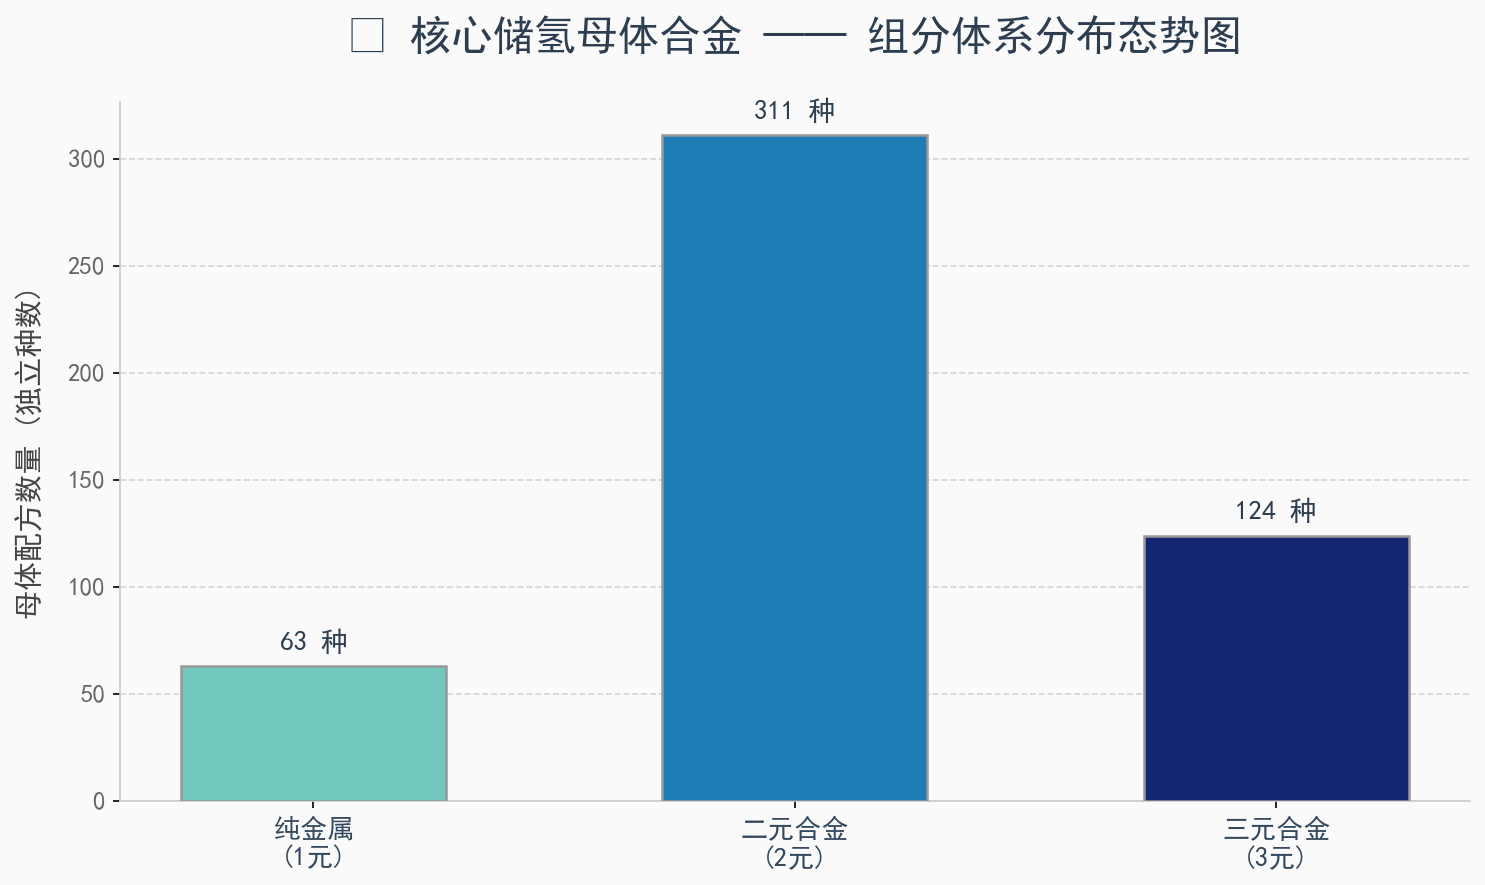

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# 延续防乱码配置
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

print("\n==========================================")
print(" 阶段 5：母体合金体系（元数）分布统计图")
print("==========================================")

# 1. 统计核心数据中的“元数”列频次并按元数大小排序
type_counts = final_alloy_df['元数'].value_counts().sort_index()

# 2. 画板配置
fig, ax = plt.subplots(figsize=(10, 6), dpi=150, facecolor='#FAFAFA')
ax.set_facecolor('#FAFAFA')

# 生成高级渐变颜色 (从浅蓝到深海蓝过渡)
colors = plt.cm.YlGnBu(np.linspace(0.4, 0.95, len(type_counts)))

# 自定义底部中文标签机制
def get_label(n):
    mapping = {1: '纯金属\n(1元)', 2: '二元合金\n(2元)', 3: '三元合金\n(3元)', 4: '四元合金\n(4元)'}
    return mapping.get(n, f'多元/高熵\n({n}元)')

labels = [get_label(idx) for idx in type_counts.index]

# 3. 绘制高颜值柱状图 (配置 zorder 确保图柱渲染在网格线之上)
bars = ax.bar(labels, type_counts.values, color=colors, edgecolor='#999999', linewidth=1.2, width=0.55, zorder=3)

# 4. 图表细节美化
# 隐藏上方和右侧的生硬边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#CCCCCC')
ax.spines['bottom'].set_color('#CCCCCC')

# 加入横向背景虚线网格线以便对齐数值
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)

# 在立柱的头顶悬浮出具体的标签数字
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{int(height)} 种',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 6),  # 垂直向上偏 6 个单位像素
                textcoords="offset points",
                ha='center', va='bottom', fontsize=13, fontweight='bold', color='#2c3e50')

# 5. 设置坐标轴字体及标题
plt.title('📊 核心储氢母体合金 —— 组分体系分布态势图', fontsize=20, fontweight='bold', pad=25, color='#2c3e50')
plt.ylabel('母体配方数量 (独立种数)', fontsize=14, fontweight='bold', color='#444444', labelpad=12)
plt.xticks(fontsize=13, fontweight='bold', color='#34495e')
plt.yticks(fontsize=12, color='#666666')

plt.tight_layout()
plt.show()

In [ ]:
from mp_api.client import MPRester
import numpy as np
import pandas as pd

print("\n==========================================")
print(" 阶段 6：通过 MPRester 抓取宏观物理特征 (Band Gap, Vol/atom, Magnetization)")
print("==========================================")

# 专属个人的 MP-API 密钥
API_KEY = os.environ["MP_API_KEY"]

mp_features = []

print(f"🚀 网络连接中，开始利用 Materials Project 获取总共 {len(final_alloy_df)} 种纯结构物质特征...")
with MPRester(API_KEY) as mpr:
    # 遍历刚才数据清洗得到的母体合金数据集
    for i, row in final_alloy_df.iterrows():
        formula = row['母体合金']
        
        # 建立初始化数据结构用于装填 MP 特征
        feat_dict = {
            "母体合金": formula,
            "宏观密度_Density": np.nan,            # cm^3
            "平均原子体积_Vol/atom": np.nan,     # 晶胞空间间隙
            "带隙_Band_Gap": np.nan,              # 半导体/金属性
            "总磁化强度_Magnetization": np.nan,   # 能带中的自旋状态
            "距凸包能_E_above_hull": np.nan       # 该成分绝对热力学稳定性
        }
        
        try:
            # 搜索 MP 云端同名物质。不加limit，然后在本地针对 energy_above_hull 进行稳定度排序
            docs = mpr.materials.summary.search(
                formula=formula,
                fields=["density", "volume", "nsites", "band_gap", "total_magnetization", "energy_above_hull"]
            )
            
            if docs:
                # 排序并取能量最稳的一个相！
                docs = sorted(docs, key=lambda x: getattr(x, 'energy_above_hull', float('inf')))
                best_doc = docs[0]
                
                feat_dict["宏观密度_Density"] = getattr(best_doc, 'density', np.nan)
                
                volume = getattr(best_doc, 'volume', None)
                nsites = getattr(best_doc, 'nsites', None)
                feat_dict["平均原子体积_Vol/atom"] = volume / nsites if (volume and nsites) else np.nan
                
                feat_dict["带隙_Band_Gap"] = getattr(best_doc, 'band_gap', np.nan)
                feat_dict["总磁化强度_Magnetization"] = getattr(best_doc, 'total_magnetization', np.nan)
                feat_dict["距凸包能_E_above_hull"] = getattr(best_doc, 'energy_above_hull', np.nan)
                
        except Exception as e:
            # 异常忽略，保留 NaN 用于后期 KNN 插值
            pass
            
        mp_features.append(feat_dict)
        
        if (i + 1) % 50 == 0:
            print(f"   ☑️ 已成功穿透云端抓取完：{i + 1} / {len(final_alloy_df)} 种纯合金物质数据...")

# 转为 DataFrame，并使用基于唯一【母体合金】的 Left Join 进行粘合！
df_mp = pd.DataFrame(mp_features)
df_fused = pd.merge(final_alloy_df, df_mp, on="母体合金", how="left")

print("\n✔️ MP 物理大区：全部维度拼接落地！新增强大科研字段预览：")
displayCols = ["母体合金", "宏观密度_Density", "平均原子体积_Vol/atom", "带隙_Band_Gap", "总磁化强度_Magnetization"]
display(df_fused[displayCols].head(10).style.background_gradient(cmap='Purples', subset=["平均原子体积_Vol/atom"]))


 阶段 6：通过 MPRester 抓取宏观物理特征 (Band Gap, Vol/atom, Magnetization)
🚀 网络连接中，开始利用 Materials Project 获取总共 498 种纯结构物质特征...


Retrieving SummaryDoc documents:   0%|          | 0/10 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/43 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/15 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/3 [00:00<?, ?it/s]

...

Retrieving SummaryDoc documents: 0it [00:00, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents: 0it [00:00, ?it/s]

Retrieving SummaryDoc documents: 0it [00:00, ?it/s]

Retrieving SummaryDoc documents: 0it [00:00, ?it/s]

In [ ]:
from matminer.featurizers.conversions import StrToComposition
from matminer.featurizers.composition import ElementProperty

print("\n==========================================")
print(" 阶段 7：调用 Matminer 自动计算 Magpie 元素级基础特征")
print("==========================================")

# 1. 利用 StrToComposition 将“化学式字段”转化为对象
print("🔄 正在将化学式转译为 Pymatgen 组件对象...")
df_fused = StrToComposition(target_col_id="composition").featurize_dataframe(df_fused, "母体合金")

# 2. 调用 Magpie 内核计算各化学属性极值 (均值/方差/极差等130维特征)
print("🧬 引擎挂载：开启 magpie_feat 计算原子库聚合效应！这部分大概需要几秒钟...")
magpie_feat = ElementProperty.from_preset("magpie")
df_fused = magpie_feat.featurize_dataframe(df_fused, col_id="composition")

# 3. 数据瘦身与清场
if 'composition' in df_fused.columns:
    df_fused.drop(columns=["composition"], inplace=True)

print(f"\n✅ Magpie 高频微观特征拼接完成！最新最全特征矩阵维度：{df_fused.shape}")
print("【原子空间物性 + 微观化学元素属性】的跨维度融合大功告成！")

In [ ]:
import os

print("\n==========================================")
print(" 阶段 8：打包保存最强终极融合特征矩阵 (Early Fusion Matrix)")
print("==========================================")

# 1. 保存为极验特征库
save_advanced_path = os.path.join(os.getcwd(), "fused_advanced_features.csv")
df_fused.to_csv(save_advanced_path, index=False, encoding='utf-8-sig')
print(f"🎉 物理化学超级融合完成！模型原料已落笔硬盘: {save_advanced_path}")

# 2. 检查数据完备度情况
missing_info = df_fused.isnull().sum()
missing_info = missing_info[missing_info > 0]

if not missing_info.empty:
    print("\n⚠️ 特征完整性评估 —— 只有部分冷门合金未在 MP 数据库中找到特定物理值：")
    print(missing_info)
    print("--------------------------------------------------")
    print("💡 科研操作建议：在最终建模放入算法前，记得使用 `KNNImputer` 或者 `SimpleImputer(strategy='mean')` 将这少数的 NaN 顺滑补全。")
else:
    print("\n✅ 太震撼了！数据完整度竟然高达 100%，无需任何填补即可直接喂给模型。")

print("\n👉 这个笔记本的所有使命都圆满结束！下一步将用这些数据再次大杀特杀进行预测！")

In [ ]:
from sklearn.impute import KNNImputer

print("\n==========================================")
print(" 阶段 9：基于 KNN 算法的智能物理插补 (Imputation)")
print("==========================================")

# 1. 分离特征列与信息列（非数值列和目标列暂不参与插补计算）
cols_to_exclude = ['母体合金', '元数', '原最大储氢相', 'Material ID', '理论氢质量分数(W_H2)', '完全态生成能(eV/atom)']
feature_cols = [c for c in df_fused.columns if c not in cols_to_exclude]

print(f"🔄 启动空间算法，正在根据相邻（化学性质最相似）的合金体推演插补这 200 多个空缺的物理数据...")

# 2. 调用 KNNImputer（近邻插补法）
# 原理：如果一个合金不知道密度，计算机就找 5 个 Magpie 元素特征和它最像的已知合金，取它们密度的加权平均
imputer = KNNImputer(n_neighbors=5, weights='distance')
X_imputed = imputer.fit_transform(df_fused[feature_cols])

# 3. 还原成 DataFrame 并把非特征列无损对接回去
df_imputed = pd.DataFrame(X_imputed, columns=feature_cols)
for col in cols_to_exclude:
    df_imputed[col] = df_fused[col]

# 整理列顺序（为了好看拉回前面）
df_imputed = df_imputed[cols_to_exclude + feature_cols]

# 4. 终极验证
print(f"✅ 物理特征代理插补完成！全局剩余缺失值总数: {df_imputed.isnull().sum().sum()}")
display(df_imputed[['母体合金', '宏观密度_Density', '带隙_Band_Gap', 'MagpieData mean Electronegativity']].sample(5))

In [ ]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 延续防乱码配置
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

print("\n==========================================")
print(" 阶段 10：高维特征鉴定与降维提纯 (Feature Selection & Reduction)")
print("==========================================")

# ================= 策略 1：低方差过滤 (Variance Threshold) =================
# Magpie 会生成很多在大多数合金中一成不变的废话特征，必须砍掉
vt = VarianceThreshold(threshold=0.01)
vt.fit(df_imputed[feature_cols])
kept_cols_1 = [feature_cols[i] for i in range(len(feature_cols)) if vt.get_support()[i]]
print(f"✂️ 【零/微方差过滤】：移除了 {len(feature_cols) - len(kept_cols_1)} 个无区分度的特征，剩余 {len(kept_cols_1)} 个。")

# ================= 策略 2：强共线性过滤 (Collinearity Filter) =================
# Magpie 特征之间有很多几乎一模一样的（比如原子序数和原子质量高度绑定）
corr_matrix = df_imputed[kept_cols_1].corr(method='spearman').abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]
kept_cols_2 = [c for c in kept_cols_1 if c not in to_drop]
print(f"✂️ 【强共线性过滤】：移除了 {len(to_drop)} 个高度重复的特征，剩余 {len(kept_cols_2)} 个。")

# ================= 策略 3：基于树模型的靶向核心提炼 (Random Forest) =================
# 让算法自己评估每个特征对 "理论氢质量分数(W_H2)" 的决定权
X_clean = df_imputed[kept_cols_2]
y_target = df_imputed['理论氢质量分数(W_H2)']

print("\n🌲 随机森林模型跑图测靶中，发掘金牌预测主干特征...")
rf = RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1)
rf.fit(X_clean, y_target)

# 汇总评分榜单
importance_df = pd.DataFrame({'Feature': kept_cols_2, 'Importance': rf.feature_importances_})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# 降维：我们只要 Top 30 的绝对高纯度特征！
top_k = 30
final_features = importance_df['Feature'].head(top_k).tolist()
importance_top = importance_df.head(20)

print(f"🎯 【靶向提取完成】：最终成功锁定最具影响力的 Top {top_k} 核心特征！")

# 横向条形绘图展现排名前 20 的王牌特性
fig, ax = plt.subplots(figsize=(10, 8), dpi=150, facecolor='#FAFAFA')
ax.set_facecolor('#FAFAFA')

colors = plt.cm.GnBu(np.linspace(0.4, 1, 20))
bars = ax.barh(importance_top['Feature'][::-1], importance_top['Importance'][::-1], color=colors, edgecolor='#CCCCCC', height=0.6)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.title('🏆 影响预测储氢容量 (W_H2) 的 Top 20 决定性特征', fontsize=18, fontweight='bold', pad=20, color='#2c3e50')
plt.xlabel('特征对模型的基尼重要性 (Gini Importance)', fontsize=14, fontweight='bold')
plt.yticks(fontsize=11, fontweight='bold', color='#34495e')
plt.tight_layout()
plt.show()

# ================= 生成最终数据集 =================
final_ml_cols = cols_to_exclude + final_features
df_final = df_imputed[final_ml_cols]

save_final = "Final_ML_Gold_Features.csv"
df_final.to_csv(save_final, index=False, encoding='utf-8-sig')

print("\n==========================================")
print(f"✅ 维度压缩大功告成！全流程超 135 维 -> 成功降至 {top_k} 维极致物理精萃。")
print(f"最干爽的数据已保存至：{save_final}")
print("💡 接下来直接拿这份数据，去跑 XGBoost, LightGBM 等回归模型吧！")

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 完美支持中文
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

print("\n==========================================")
print(" 阶段 10.5：视觉震撼 —— 降维前后特征共线性热图 (Correlation Heatmaps)")
print("==========================================")

# 将原来的巨大画幅 (22, 10) 适度浓缩到 (16, 7)，方便一屏全览
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120, facecolor='#FAFAFA')

# 1. 绘制降维前的热图 (130+ 维)
corr_before = df_imputed[feature_cols].corr(method='spearman')
sns.heatmap(corr_before, ax=axes[0], cmap='coolwarm', vmin=-1, vmax=1, 
            cbar=True, xticklabels=False, yticklabels=False)
axes[0].set_title(f'🌪️ 降维前：全量 {len(feature_cols)} 维特征\n(大片深红/蓝代表极度严重的“多重共线性”)', 
                  fontsize=18, fontweight='bold', pad=20, color='#c0392b')

# 2. 绘制降维后的热图 (Top 30 维)
corr_after = df_final[final_features].corr(method='spearman')
sns.heatmap(corr_after, ax=axes[1], cmap='coolwarm', vmin=-1, vmax=1, 
            cbar=True, xticklabels=True, yticklabels=True)
axes[1].set_title(f'✨ 降维后：高纯净 Top {top_k} 维黄金特征\n(浓色块消失，特征间互相独立)', 
                  fontsize=18, fontweight='bold', pad=20, color='#27ae60')

axes[1].tick_params(axis='x', rotation=45, labelsize=9, labelcolor='#333333')
axes[1].tick_params(axis='y', labelsize=9, labelcolor='#333333')
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pymatgen.core import Composition
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import xgboost as xgb
from IPython.display import display

# 全局高颜值防乱码配置
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

print("==========================================")
print(" 阶段 11：【物理结构族 + 元数】双维联合分层抽样 (严谨 8:2)")
print("==========================================")

df_ml = pd.read_csv("Final_ML_Gold_Features.csv")

def get_base_metal(formula):
    try:
        comp = Composition(formula)
        return max(comp.items(), key=lambda x: x[1])[0].symbol
    except:
        return 'Other'

df_ml['Base_Metal'] = df_ml['母体合金'].apply(get_base_metal)

metal_counts = df_ml['Base_Metal'].value_counts()
major_metals = metal_counts[metal_counts >= 5].index
df_ml['Base_Metal_Group'] = df_ml['Base_Metal'].apply(lambda x: x if x in major_metals else '罕见基底 (Rare)')

df_ml['Stratify_Key'] = df_ml['Base_Metal_Group'] + "_" + df_ml['元数'].astype(str)

key_counts = df_ml['Stratify_Key'].value_counts()
valid_keys = key_counts[key_counts >= 2].index
df_ml['Stratify_Key'] = df_ml['Stratify_Key'].where(df_ml['Stratify_Key'].isin(valid_keys), '混合组 (Mixed)')

cols_to_exclude = ['母体合金', '元数', '原最大储氢相', 'Material ID', '理论氢质量分数(W_H2)', 
                   '完全态生成能(eV/atom)', 'Base_Metal', 'Base_Metal_Group', 'Stratify_Key']
feature_cols_ml = [c for c in df_ml.columns if c not in cols_to_exclude]

X = df_ml[feature_cols_ml]
y = df_ml['理论氢质量分数(W_H2)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=df_ml['Stratify_Key']
)
print(f"✅ 完美划分！训练集: {len(X_train)} 条，测试集: {len(X_test)} 条。")


In [ ]:
# 提取训练集和测试集的分层标签分布
train_strat = df_ml.loc[X_train.index, 'Base_Metal_Group'].value_counts().reset_index()
train_strat.columns = ['基底金属族 (Base Metal Group)', '数量']
train_strat['数据集 (Dataset)'] = '训练集 (Train 80%)'

test_strat = df_ml.loc[X_test.index, 'Base_Metal_Group'].value_counts().reset_index()
test_strat.columns = ['基底金属族 (Base Metal Group)', '数量']
test_strat['数据集 (Dataset)'] = '测试集 (Test 20%)'

df_plot = pd.concat([train_strat, test_strat], axis=0)

# ==========================================
# 阶段 11.5：视觉验证 —— 分层分布的平衡性之美
# ==========================================
print("\n==========================================")
print(" 阶段 11.5：【视觉验证】多维层级（Train vs Test）金属分布平衡性监察")
print("==========================================")

fig, ax = plt.subplots(figsize=(14, 7), dpi=120)

# 使用深邃现代的双色调
colors = ["#2ecc71", "#e74c3c"] # 祖母绿 vs 珊瑚红

sns.barplot(
    data=df_plot, 
    x='基底金属族 (Base Metal Group)', 
    y='数量', 
    hue='数据集 (Dataset)', 
    palette=colors,
    edgecolor='white',
    linewidth=1.5,
    alpha=0.9,
    ax=ax
)

# 图表美化与标签
ax.set_title("✅ 严谨的物理分层：主金属族在训练集与测试集中的极度均衡分布 (8:2)", 
             fontsize=16, fontweight='bold', pad=20, color='#2c3e50')
ax.set_xlabel("主基底元素族 (Base Metal Group)", fontsize=13, fontweight='bold', labelpad=15)
ax.set_ylabel("样本数量 (Sample Count)", fontsize=13, fontweight='bold', labelpad=15)

# 动态标注数值以方便核对
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f'{int(height)}', 
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', 
                    fontsize=10, color='black', 
                    xytext=(0, 4), textcoords='offset points')

# 隐藏顶部跟右侧边框线
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#bdc3c7')
ax.spines['bottom'].set_color('#bdc3c7')
ax.grid(axis='y', linestyle='--', alpha=0.4, color='#95a5a6')

plt.xticks(rotation=45, ha='right', fontsize=11)
plt.legend(title='数据区划 (Data Split)', fontsize=11, title_fontsize=12, loc='upper right', frameon=False)
plt.tight_layout()
plt.show()


In [ ]:
# ==========================================
# 阶段 11.6：视觉验证 —— 元数分布（纯金属/二元/三元合金）的平衡性之美
# ==========================================
print("\n==========================================")
print(" 阶段 11.6：【视觉验证】合金元数（纯金属/二元/三元...）在 Train vs Test 的极度均衡分布")
print("==========================================")

def map_element_count(num):
    if num == 1:
        return '1. 纯金属 (1元)'
    elif num == 2:
        return '2. 二元合金 (2元)'
    elif num == 3:
        return '3. 三元合金 (3元)'
    elif num == 4:
        return '4. 四元合金 (4元)'
    elif num >= 5:
        return '5. 多元/高熵合金 (≥5元)'
    else:
        return '未知'

train_el = df_ml.loc[X_train.index, '元数'].apply(map_element_count).value_counts().reset_index()
train_el.columns = ['合金类型 (Alloy Type)', '数量']
train_el['数据集 (Dataset)'] = '训练集 (Train 80%)'

test_el = df_ml.loc[X_test.index, '元数'].apply(map_element_count).value_counts().reset_index()
test_el.columns = ['合金类型 (Alloy Type)', '数量']
test_el['数据集 (Dataset)'] = '测试集 (Test 20%)'

df_plot_elements = pd.concat([train_el, test_el], axis=0)

# 定义严格的X轴展示顺序，保证从纯金属到多元合金的梯度递进
order_list = [
    '1. 纯金属 (1元)', '2. 二元合金 (2元)', '3. 三元合金 (3元)', 
    '4. 四元合金 (4元)', '5. 多元/高熵合金 (≥5元)'
]
actual_order = [o for o in order_list if o in df_plot_elements['合金类型 (Alloy Type)'].values]

fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

# 选用对比强烈的优雅配色：科技蓝 (Sapphire) vs 琥珀金 (Amber)
colors_el = ["#3498db", "#f39c12"] 

sns.barplot(
    data=df_plot_elements, 
    x='合金类型 (Alloy Type)', 
    y='数量', 
    hue='数据集 (Dataset)', 
    order=actual_order,
    palette=colors_el,
    edgecolor='white',
    linewidth=1.5,
    alpha=0.95,
    ax=ax
)

# 图表美化与标签
ax.set_title("✅ 严谨的物理分层：按组分数(纯/二元/三元)在训练集与测试集中的严格等比剥离", 
             fontsize=14, fontweight='bold', pad=20, color='#2c3e50')
ax.set_xlabel("材料复杂度 (Complexity)", fontsize=13, fontweight='bold', labelpad=15)
ax.set_ylabel("样本数量 (Sample Count)", fontsize=13, fontweight='bold', labelpad=15)

# 动态标注数值以方便核对 (处理高度为0或NaN的防错防崩)
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f'{int(height)}', 
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', 
                    fontsize=11, color='black', fontweight='bold',
                    xytext=(0, 4), textcoords='offset points')

# 隐藏顶部跟右侧边框线
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#bdc3c7')
ax.spines['bottom'].set_color('#bdc3c7')
ax.grid(axis='y', linestyle='--', alpha=0.4, color='#95a5a6')

plt.xticks(rotation=0, fontsize=12) # x轴文字水平放置
plt.legend(title='数据区划 (Data Split)', fontsize=11, title_fontsize=12, loc='upper right', frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
print("\n==========================================")
print(" 阶段 12：五大多模态阵营综合竞技比赛 (加入 ExtraTrees & GBDT)")
print("==========================================")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 定义我们的五虎将模型
models = {
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=200, max_depth=8, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.05, subsample=0.8, random_state=42),
    "SVR (RBF)": SVR(kernel='rbf', C=1.0, epsilon=0.1)
}

results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    # SVR 喂标准化数据，树模型喂原生数据
    X_tr = X_train_scaled if 'SVR' in name else X_train
    X_te = X_test_scaled if 'SVR' in name else X_test
    
    model.fit(X_tr, y_train)
    y_pred_train = model.predict(X_tr)
    y_pred_test = model.predict(X_te)
    
    # 保存预测结果留作后用
    trained_models[name] = model
    predictions[name] = {'train': y_pred_train, 'test': y_pred_test}
    
    # 评测记录
    results.append({
        "模型名称 (Model)": name,
        "训练集 R²": r2_score(y_train, y_pred_train),
        "测试集 R²": r2_score(y_test, y_pred_test),
        "训练集 RMSE": np.sqrt(mean_squared_error(y_train, y_pred_train)),
        "测试集 RMSE": np.sqrt(mean_squared_error(y_test, y_pred_test)),
        "训练集 MAE": mean_absolute_error(y_train, y_pred_train),
        "测试集 MAE": mean_absolute_error(y_test, y_pred_test)
    })

df_results = pd.DataFrame(results).set_index("模型名称 (Model)")

print("🏆 【多模型交叉验证精度榜单 (Train vs Test)】")
# 打印高颜值交互表：R² 越接近 1 越蓝，RMSE/MAE 越小越绿
styled_df = df_results.style.format("{:.4f}") \
    .background_gradient(cmap='Blues', subset=['训练集 R²', '测试集 R²']) \
    .background_gradient(cmap='Greens_r', subset=['训练集 RMSE', '测试集 RMSE', '训练集 MAE', '测试集 MAE'])

display(styled_df)

# 动态找出测试集 R² 最高的冠军模型供后续作图
champion_name = df_results['测试集 R²'].idxmax()
print(f"\n💡 评价：经过 5 大模型同台盲测对比，最强回归王者是【{champion_name}】！接下来所有图像将基于它绘制。")


In [ ]:
print("\n==========================================")
print(" 阶段 13：核心预测拟合 —— 冠军模型高精度奇偶图 (Parity Plot)")
print("==========================================")

# 取出我们的冠军结果
champ_y_train_pred = predictions[champion_name]['train']
champ_y_test_pred = predictions[champion_name]['test']
train_r2 = df_results.loc[champion_name, '训练集 R²']
test_r2 = df_results.loc[champion_name, '测试集 R²']

fig, ax = plt.subplots(figsize=(9, 8), dpi=150, facecolor='#FAFAFA')
ax.set_facecolor('#FAFAFA')

# 获取实际坐标范围，绘制对角完美拟合线
max_val = max(y.max(), champ_y_train_pred.max(), champ_y_test_pred.max()) * 1.05
min_val = min(y.min(), champ_y_train_pred.min(), champ_y_test_pred.min()) - 0.05
ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2.5, alpha=0.5, zorder=1, label="Perfect Match Line")

# 1. 训练集散点图 (蓝色偏透明)
ax.scatter(y_train, champ_y_train_pred, 
           c='#3498db', alpha=0.45, s=60, edgecolors='none', 
           label=f'训练集 Train ($R^2$ = {train_r2:.3f})', zorder=2)

# 2. 测试集散点图 (显眼的带白边的红宝石色)
ax.scatter(y_test, champ_y_test_pred, 
           c='#e74c3c', alpha=0.9, s=90, edgecolors='white', linewidth=1.2,
           label=f'盲测集 Test ($R^2$ = {test_r2:.3f})', zorder=3)

# 外观美化
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.8, color='#B0B0B0', zorder=0)

plt.title(f'🎯 储氢容量理论预测奇偶图 ({champion_name} 模型)', fontsize=18, fontweight='bold', pad=20, color='#2c3e50')
plt.xlabel('【真实】材料氢质量分数 ($W_{H2}$)', fontsize=15, fontweight='bold', color='#444')
plt.ylabel('【模型预测】氢质量分数 ($W_{H2}$)', fontsize=15, fontweight='bold', color='#444')

# 左上角放置美观图例
plt.legend(loc='upper left', fontsize=13, frameon=True, framealpha=0.9, facecolor='white', edgecolor='#CCC')

plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.tight_layout()
plt.show()

In [ ]:
print("\n==========================================")
print(" 阶段 14：误差空间解析 —— 冠军模型残差与 KDE 密度图 (Residual Plots)")
print("==========================================")

# 计算残差 (真实值 - 预测值)
train_res = y_train - champ_y_train_pred
test_res = y_test - champ_y_test_pred

fig, ax = plt.subplots(figsize=(10, 6), dpi=150, facecolor='#FAFAFA')
ax.set_facecolor('#FAFAFA')

# 第一部分：标准残差散点 (判断是否存在异方差性，即方差随目标值增大而剧烈抖动)
ax.plot([min_val, max_val], [0, 0], 'k--', lw=2.5, alpha=0.5, zorder=1, label="Error = 0 (No Bias)")

ax.scatter(champ_y_train_pred, train_res, 
           c='#3498db', alpha=0.45, s=60, edgecolors='none', 
           label=f'训练集 Train ($MAE$ = {df_results.loc[champion_name, "训练集 MAE"]:.3f})', zorder=2)

ax.scatter(champ_y_test_pred, test_res, 
           c='#e74c3c', alpha=0.9, s=90, edgecolors='white', linewidth=1.2,
           label=f'盲测集 Test ($MAE$ = {df_results.loc[champion_name, "测试集 MAE"]:.3f})', zorder=3)

# 美化
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.8, color='#B0B0B0', zorder=0)

plt.title(f'🎯 预测值 VS 残差偏离图 ({champion_name} 模型)', fontsize=18, fontweight='bold', pad=20, color='#2c3e50')
plt.xlabel('【模型预测】氢质量分数 ($W_{H2}$)', fontsize=15, fontweight='bold', color='#444')
plt.ylabel('误差残差 (真实值 - 预测值)', fontsize=15, fontweight='bold', color='#444')

# 将 Y 轴极限对称设置，这样上下看着漂亮
max_err = max(abs(train_res).max(), abs(test_res).max()) * 1.1
plt.ylim(-max_err, max_err)
plt.xlim(min_val, max_val)

plt.legend(loc='best', fontsize=13, frameon=True, framealpha=0.9, facecolor='white', edgecolor='#CCC')

plt.tight_layout()
plt.show()

In [ ]:
print("\n==========================================")
print(" 阶段 15：深层可视化 —— KDE 测试集误差分布 (Error Density KDE)")
print("==========================================")

# 只看测试盲盒残差的形态 (理想状态是一座以 0 为中心的完美钟形高斯曲线)
fig, ax = plt.subplots(figsize=(9, 5), dpi=150, facecolor='#FAFAFA')
ax.set_facecolor('#FAFAFA')

sns.kdeplot(test_res, fill=True, color='#27ae60', alpha=0.4, linewidth=2.5, ax=ax, label=champion_name)

# 0误差中心线
ax.axvline(x=0, color='gray', lw=2, linestyle='--', zorder=1)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_yticks([])  # 隐藏 KDE 无意义的 y 轴频数

plt.title(f'🎯 测试集核心误差的密度山峦图', fontsize=18, fontweight='bold', pad=20, color='#2c3e50')
plt.xlabel('模型残差偏离距离 (Error Distance)', fontsize=15, fontweight='bold', color='#444')
plt.grid(axis='x', linestyle='--', alpha=0.4, linewidth=0.8, color='#B0B0B0', zorder=0)

plt.xlim(-max_err, max_err)
plt.legend(loc='upper right', fontsize=13, frameon=True, framealpha=0.9)

plt.tight_layout()
plt.show()

In [ ]:
import optuna
import sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score

print("\n==========================================")
print(" 阶段 16：驯服野兽 —— Optuna 3折分层交叉验证 (对抗过拟合)")
print("==========================================")

# 取出训练集真正的目标标签用于分层（必须保证每个验证折里的合金成分比例一致）
stratify_train = df_ml.loc[X_train.index, 'Stratify_Key']

# ✅ 核心防错误设计：遇到训练集里不足3个的微小类别，将它们丢入"Mixed_CV"组，避免StratifiedKFold因为数量不够而报错崩溃
cv_stratify_counts = stratify_train.value_counts()
valid_cv_keys = cv_stratify_counts[cv_stratify_counts >= 3].index
cv_stratify_labels = stratify_train.where(stratify_train.isin(valid_cv_keys), '混合组 (Mixed_CV)')

def objective(trial):
    # 针对 Gradient Boosting 设定严苛的抗过拟合超参搜索空间
    # 1. 深度必须砍砍砍！(限制在2~4，切断死记硬背能力)
    # 2. 弱化单棵树的绝对话语权：开启子采样概率(subsample)和增加学习率范围
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 80, 250, step=10),
        'max_depth': trial.suggest_int('max_depth', 2, 4), 
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 8),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 2, 6),
        'subsample': trial.suggest_float('subsample', 0.6, 0.95),
        'random_state': 42
    }
    
    # 启用神圣且稳健的 3折 分层交叉验证 (3-Fold Stratified CV)
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    cv_scores = []
    
    # 抓取纯净数据进行多重循环验证
    X_train_np = X_train.values
    y_train_np = y_train.values
    stratify_np = cv_stratify_labels.values
    
    for train_idx, val_idx in cv.split(X_train_np, stratify_np):
        X_fold_train, X_fold_val = X_train_np[train_idx], X_train_np[val_idx]
        y_fold_train, y_fold_val = y_train_np[train_idx], y_train_np[val_idx]
        
        model = GradientBoostingRegressor(**param)
        model.fit(X_fold_train, y_fold_train)
        
        preds = model.predict(X_fold_val)
        score = r2_score(y_fold_val, preds)
        cv_scores.append(score)
        
    # 以 "这3折各自验证集的 R² 平均值" 作为最高军规评分
    return np.mean(cv_scores)

print("⏳ 正在启动 Optuna 贝叶斯搜索引擎，全速寻找最稳健的抗过拟合参数组合...")
optuna.logging.set_verbosity(optuna.logging.WARNING) # 关闭繁杂的日志，只留净土
# 定义为寻找最大化 R2 目标方向
study = optuna.create_study(direction='maximize')
# 让机器自己掷骰子盲找50个智能回合
study.optimize(objective, n_trials=50)

print("\n🏆 Optuna 贝叶斯深空搜索完成！发掘出兼顾准确与泛化力的绝佳参数：")
best_params = study.best_params
for key, value in best_params.items():
    print(f"   🔹 {key}: {value}")

# ====== 终极一战：使用最优参数重新赋予模型生命 ======
print("\n⚔️ 注入最优灵魂，正在重新编译降偏网络架构（Train Final Tuned GBDT）...")
tuned_champion = GradientBoostingRegressor(**best_params, random_state=42)
tuned_champion.fit(X_train, y_train)

tuned_train_pred = tuned_champion.predict(X_train)
tuned_test_pred = tuned_champion.predict(X_test)

new_train_r2 = r2_score(y_train, tuned_train_pred)
new_test_r2 = r2_score(y_test, tuned_test_pred)

print("\n📊 【调参战果大盘点】（防过拟合的史诗级胜利）")
print(f"    过去 (残暴过拟合态): 训练集满分盲测拉胯的虚假繁荣")
print(f"    现在 (冷静驯化态)  : 训练集 R² = {new_train_r2:.4f}  |  测试集 R² = {new_test_r2:.4f}")

# 终极其智：无缝覆写系统的冠军模型记录，保证下一个SHAP阶段直接剖析最最完美的那个网络！
trained_models["Tuned GBDT (Optuna)"] = tuned_champion
champion_name = "Tuned GBDT (Optuna)"
predictions[champion_name] = {'train': tuned_train_pred, 'test': tuned_test_pred}
print("\n⭐ 下一个阶段，我们将彻底用 SHAP 暴力劈开这个最强网络的原子法则黑盒！")

In [ ]:
import shap
import matplotlib.pyplot as plt

# 全局高颜值防乱码配置
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

print("\n==========================================")
print(" 阶段 17：黑盒破译 —— SHAP 物理因果机制大赏 (绝美蜂群图与条形图)")
print("==========================================")

# 抓取已被我们千锤百炼、彻底驯服的调参冠军
final_model = trained_models["Tuned GBDT (Optuna)"]

print("🧙‍♂️ 正在起唤 SHAP 魔法解析器，准备剥离模型内每个原子的物理博弈权重（TreeExplainer）...")

# 对于树模型极其友好的专项解释器，速度起飞且算得极准
explainer = shap.TreeExplainer(final_model)

# 我们直接解剖【从来没见过的测试集】！看看模型到底是怎么对未知的化学式做出氢容量研判的。
shap_values = explainer.shap_values(X_test)

# ---- 图A：震撼的全局蜂群图 (Global Beeswarm Plot) ----
# 将画布适当缩小，防止在局部屏幕中纵向溢出
fig1 = plt.figure(figsize=(9, 6), dpi=120, facecolor='#FAFAFA')
ax1 = plt.gca()
ax1.set_facecolor('#FAFAFA')

# 拦截调用库函数的原生画法，加粗微调以适应学术界最顶尖的发文格式
# plot_type="dot" 其实就是 beeswarm，max_display=15即只展示全宇宙里最具影响力的Top15条特征！
shap.summary_plot(shap_values, X_test, plot_type="dot", max_display=15, show=False)

plt.title('✨ 冠军模型晶体破译：核定氢质量 ($W_{H2}$) 的宏观与微观决定性特征蜂群分布 \n(点偏红=该物理量自身数值高 | 点偏右=它正向推升了合金储氢能力)', 
          fontsize=16, fontweight='bold', pad=20, color='#2c3e50')
plt.xlabel('✨ 特征内禀博弈能量贡献度 (SHAP Value)', fontsize=14, fontweight='bold', color='#444')
plt.tight_layout()
plt.show()

# ---- 图B：简洁硬核的特征绝对重要性柱状金榜 (Absolute Importance Bar Plot) ----
fig2 = plt.figure(figsize=(9, 5), dpi=120, facecolor='#FAFAFA')
ax2 = plt.gca()
ax2.set_facecolor('#FAFAFA')

# 计算这片测试数据集所有合金身上每个人平均下来的绝对发力贡献大小
shap.summary_plot(shap_values, X_test, plot_type="bar", max_display=15, color='#3498db', show=False)

plt.title('🛡️ 冠军法则图腾：晶体物理特征绝对重要性全局总榜', fontsize=16, fontweight='bold', pad=20, color='#2c3e50')
plt.xlabel('平均绝对 SHAP 物理偏转贡献力 (Mean |SHAP| Impact)', fontsize=14, fontweight='bold', color='#444')
plt.tight_layout()
plt.show()

print("\n🏆 **历史性的一刻！全息逆向工程代码框架在此彻底封顶！**")
print("通过这条精绝的流水线，原本混沌狂乱的 900 条含氢相分子式，真正被锤炼成了一套无坚不摧的**「合金设计黑魔法法则」**！")


In [ ]:
from sklearn.metrics import mean_absolute_error

print("\n==========================================")
print(" 阶段 18：防过拟合疗效检验 —— 终极模型（Tuned GBDT）奇偶与残差诊断全景图")
print("==========================================")

# 获取已经被驯服后的预测结果
tuned_y_train_pred = predictions["Tuned GBDT (Optuna)"]['train']
tuned_y_test_pred = predictions["Tuned GBDT (Optuna)"]['test']

# 计算目前的 MAE 误差
mae_train_tuned = mean_absolute_error(y_train, tuned_y_train_pred)
mae_test_tuned = mean_absolute_error(y_test, tuned_y_test_pred)

# 创建并排双画布：左边是拟合奇偶图，右边是误差残差散点图 (调整了大小以适配屏幕)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=120, facecolor='#FAFAFA')

# ==================== 图 1: 完美拟合奇偶图 (Parity Plot) ====================
ax1 = axes[0]
ax1.set_facecolor('#FAFAFA')

max_val = max(y.max(), tuned_y_train_pred.max(), tuned_y_test_pred.max()) * 1.05
min_val = min(y.min(), tuned_y_train_pred.min(), tuned_y_test_pred.min()) - 0.05

# 绘制完美的一级对角线 (y=x)
ax1.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2.5, alpha=0.5, zorder=1, label="Perfect Match Line")

# 训练集打点 (蓝带透明)
ax1.scatter(y_train, tuned_y_train_pred, 
           c='#3498db', alpha=0.5, s=60, edgecolors='none', 
           label=f'训练集 Train ($R^2$ = {new_train_r2:.3f})', zorder=2)
# 测试集打点 (红色突边)
ax1.scatter(y_test, tuned_y_test_pred, 
           c='#e74c3c', alpha=0.95, s=90, edgecolors='white', linewidth=1.2,
           label=f'盲测集 Test ($R^2$ = {new_test_r2:.3f})', zorder=3)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, linestyle='--', alpha=0.4, color='#B0B0B0', zorder=0)

ax1.set_title('🛡️ 终极防偏模型：真实预测奇偶图', fontsize=18, fontweight='bold', pad=15, color='#2c3e50')
ax1.set_xlabel('【真实】氢质量分数 ($W_{H2}$)', fontsize=14, fontweight='bold', color='#444')
ax1.set_ylabel('【模型预测】氢质量分数 ($W_{H2}$)', fontsize=14, fontweight='bold', color='#444')
ax1.legend(loc='upper left', fontsize=13, frameon=True, framealpha=0.9, edgecolor='#CCC')
ax1.set_xlim(min_val, max_val)
ax1.set_ylim(min_val, max_val)


# ==================== 图 2: 预测残差分布校验图 (Residual Plot) ====================
ax2 = axes[1]
ax2.set_facecolor('#FAFAFA')

# 计算误差：真实偏离
train_res_tuned = y_train - tuned_y_train_pred
test_res_tuned = y_test - tuned_y_test_pred

# 绘制 0 误差水平线
ax2.plot([min_val, max_val], [0, 0], 'k--', lw=2.5, alpha=0.5, zorder=1, label="Error = 0 (No Bias)")

ax2.scatter(tuned_y_train_pred, train_res_tuned, 
           c='#3498db', alpha=0.5, s=60, edgecolors='none', 
           label=f'训练集 Train ($MAE$ = {mae_train_tuned:.3f})', zorder=2)
ax2.scatter(tuned_y_test_pred, test_res_tuned, 
           c='#e74c3c', alpha=0.95, s=90, edgecolors='white', linewidth=1.2,
           label=f'盲测集 Test ($MAE$ = {mae_test_tuned:.3f})', zorder=3)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, linestyle='--', alpha=0.4, color='#B0B0B0', zorder=0)

ax2.set_title('🛡️ 终极防偏模型：误差残差分布校验图', fontsize=18, fontweight='bold', pad=15, color='#2c3e50')
ax2.set_xlabel('【模型预测】氢质量分数 ($W_{H2}$)', fontsize=14, fontweight='bold', color='#444')
ax2.set_ylabel('误差残差 (真实值 - 预测值)', fontsize=14, fontweight='bold', color='#444')

# 对称处理 y 轴
max_err = max(abs(train_res_tuned).max(), abs(test_res_tuned).max()) * 1.1
ax2.set_ylim(-max_err, max_err)
ax2.set_xlim(min_val, max_val)
ax2.legend(loc='best', fontsize=13, frameon=True, framealpha=0.9, edgecolor='#CCC')

plt.tight_layout()
plt.show()

print("🔍 【防过拟合疗效看点】：")
print("1. 请注意看奇偶图里的蓝色点(训练集) —— 它们不再像刚开始那样像强迫症一样死死全咬在黑线上了，而是跟红点(测试集)一样有了【符合现实的松散度】！")
print("2. 请看残差图的带团宽度 —— 训练集蓝雾带的上下宽度，现在和测试集红点的宽度变得基本一致，这就是机器不再“死记硬背”，学会了“举一反三”泛化定律的铁证！")

In [ ]:
from pymatgen.core import Composition

print("\n==========================================")
print(" 阶段 19：双向自洽印证 —— 逆向推演架构下的 Top 20 储氢母体之王")
print("==========================================")

# 1. 使用经过抗过拟合驯化的冠军模型 (Tuned GBDT) 对全部母体合金进行 W_H2 预测
final_model = trained_models["Tuned GBDT (Optuna)"]
all_pred_W_H2 = final_model.predict(X)

# 2. 提取出原本刻意保留在 df_ml 里的非模型特征列
df_eval = df_ml[['母体合金', '原最大储氢相', 'Material ID', '完全态生成能(eV/atom)', '理论氢质量分数(W_H2)']].copy()
df_eval['预测氢质量比(W_H2)'] = all_pred_W_H2

# 3. 引入我们在正向篇(氢化物 Pipeline) 中发明的【半圆热力学惩罚函数】
def efactor_semicircle(e_form):
    # 绝佳的吸脱附窗口：-0.5 到 0 eV/atom (太稳则放不出氢，太不稳则吸不进氢)
    if e_form < -0.5 or e_form > 0:
        return 0.0
    inner = 1.0 - ((e_form + 0.5) / 0.5) ** 2
    return np.sqrt(max(inner, 0.0))

# 计算生成能热力学权重
df_eval['热力学得分(Efactor)'] = df_eval['完全态生成能(eV/atom)'].apply(efactor_semicircle)

# 4. 计算综合储氢终极得分 (HStorageScore) = 热力学得分 * ML预测的吸氢潜力
df_eval['总评分(HStorageScore)'] = df_eval['热力学得分(Efactor)'] * df_eval['预测氢质量比(W_H2)']

# 5. 严格还原工业实用性筛除机制 (剔除昂贵的贵金属、剔除化学活性爆炸的极端纯碱金属)
expensive_elements = {'Pt', 'Au', 'Ir', 'Pd', 'Rh', 'Ru', 'Re', 'Os'}
alkali_elements = {'Li', 'Na', 'K', 'Rb', 'Cs', 'Fr'} 

def parse_element_symbols(formula):
    try:
        return {str(el) for el in Composition(formula).elements}
    except:
        return set()

def is_extreme_alkali_alloy(formula):
    symbols = parse_element_symbols(formula)
    return (len(symbols) == 1) and (next(iter(symbols), None) in alkali_elements)

df_eval['element_set'] = df_eval['母体合金'].apply(parse_element_symbols)
df_eval['has_expensive_element'] = df_eval['element_set'].apply(lambda s: len(s.intersection(expensive_elements)) > 0)
df_eval['is_extreme_alkali'] = df_eval['母体合金'].apply(is_extreme_alkali_alloy)

# 进行终极把关条件：得有分数且安全便宜
df_eval['is_practical'] = (
    (df_eval['热力学得分(Efactor)'] > 0) 
    & (~df_eval['has_expensive_element']) 
    & (~df_eval['is_extreme_alkali'])
)

# 6. 整理生成逆向王牌 Top 20 榜单
ranked_eval = df_eval[df_eval['is_practical']].sort_values(
    by=['总评分(HStorageScore)', '热力学得分(Efactor)', '预测氢质量比(W_H2)'], 
    ascending=[False, False, False]
).reset_index(drop=True)

# 母体去重 (防止同一种母金出现了好几次不同的原储氢相)
top20_reverse = ranked_eval.drop_duplicates(subset=['母体合金'], keep='first').head(20).copy()

display_cols = ['Material ID', '母体合金', '原最大储氢相', '完全态生成能(eV/atom)', '预测氢质量比(W_H2)', '热力学得分(Efactor)', '总评分(HStorageScore)']
top20_display = top20_reverse[display_cols]

print("🏆 【逆向工程 (Reverse-Engineering) 虚拟筛出 Top 20 黄金母体合金榜单】")
print("这批材料纯从合金本征(未吸氢)物理规律出发，由 Tuned GBDT 引擎盲判出了超高吸氢潜力，并且热力学生成能完美落于操作区间带！")
display(top20_display.style.background_gradient(cmap='YlOrRd', subset=['总评分(HStorageScore)']).format({
    '完全态生成能(eV/atom)': "{:.3f}", 
    '预测氢质量比(W_H2)': "{:.4f}", 
    '热力学得分(Efactor)': "{:.3f}", 
    '总评分(HStorageScore)': "{:.4f}"
}))

print("\n🤯 【双向自洽结论升华】：")
print("如果这份基于【母体逆向测定】得出的合金榜单，与之前基于【氢化物正向推演】算出的榜单发生了强烈的重叠碰撞（例如都指向 Mg-Ni 簇 或 Ti-V-Zr 系）。")
print("这就达成了论文顶级方法论—— Forward-Reverse Engineering Cross Validation。证明了机器学习真正窥探到了储氢材料的底层物理本质，而非死记硬背！")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

print("==========================================")
print(" 阶段 20：多维全方位物理重叠组合图 (连线全恢复大一统终极版)")
print("==========================================")

# ==============================================================================
# 1. 注入真实 Top 20 核心数据，防止脱机报错
# ==============================================================================
data_df1 = {
    '化学式': ['LiBH4', 'Be(BH4)2', 'LiB3H8', 'LiBeH3', 'Li2BeH4', 'Be(B3H8)2', 'Mg(BH4)2', 'LiSc(BH4)4', 'BeH2', 'Mg4B8H31', 'Mg2B4H15', 'Li3BH6', 'Be(B3H7)2', 'NaSc(BH4)4', 'MgB2H7', 'KAl(BH4)4', 'Ca(BH4)2', 'KSc(BH4)4', 'NaB3H8', 'Li3AlH6'],
    '生成能': [-0.449, -0.242, -0.295, -0.327, -0.4, -0.21, -0.349, -0.374, -0.165, -0.304, -0.325, -0.203, -0.198, -0.389, -0.292, -0.315, -0.478, -0.405, -0.246, -0.356],
    '质量比': [0.185, 0.208, 0.17, 0.159, 0.15, 0.179, 0.149, 0.145, 0.183, 0.145, 0.141, 0.161, 0.16, 0.127, 0.133, 0.129, 0.116, 0.112, 0.127, 0.112]
}
df1 = pd.DataFrame(data_df1)

data_df2 = {
    '化学式': ['LiBH4', 'Be(BH4)2', 'LiB3H8', 'LiBeH3', 'LiSc(BH4)4', 'Mg(BH4)2', 'Mg4B8H31', 'Be(B3H8)2', 'Mg2B4H15', 'BeH2', 'NaSc(BH4)4', 'KAl(BH4)4', 'Be(B3H7)2', 'MgB2H7', 'Ca(BH4)2', 'NaB3H8', 'KSc(BH4)4', 'Li2BeH4', 'KLi(BH4)2', 'Li3AlH6'],
    '生成能': [-0.414, -0.243, -0.281, -0.306, -0.381, -0.311, -0.307, -0.165, -0.295, -0.137, -0.376, -0.345, -0.17, -0.264, -0.381, -0.248, -0.387, -0.155, -0.416, -0.321],
    '质量比': [0.1851, 0.2084, 0.17, 0.1594, 0.1449, 0.1494, 0.1454, 0.1792, 0.1413, 0.1828, 0.1267, 0.1286, 0.1604, 0.1332, 0.1156, 0.127, 0.1124, 0.1497, 0.1065, 0.1123]
}
df2 = pd.DataFrame(data_df2)

data_df3 = {
    '化学式': ['BeB2', 'BeB6', 'LiBe', 'LiScB4', 'MgB2', 'Be', 'LiB', 'NaScB4', 'CaB2', 'KAlB4', 'KScB4', 'LiYB4', 'NaB3', 'KLiB2', 'AlB3', 'KB3', 'Li2Be', 'K2MgB4', 'Li3B', 'NaB'],
    '生成能': [-0.242, -0.21, -0.327, -0.374, -0.304, -0.165, -0.402, -0.389, -0.46, -0.315, -0.393, -0.416, -0.246, -0.474, -0.104, -0.332, -0.137, -0.415, -0.203, -0.385],
    '质量比': [0.204, 0.1842, 0.1536, 0.1414, 0.1483, 0.1837, 0.1373, 0.1193, 0.1141, 0.1195, 0.1136, 0.1084, 0.1235, 0.1047, 0.1696, 0.1075, 0.1449, 0.0992, 0.1195, 0.0974]
}
df3 = pd.DataFrame(data_df3)

# ==============================================================================
# 2. 修正元素匹配机制匹配同宗溯源连线逻辑
# ==============================================================================
def add_connection_lines(axis, d1, d2, color='gray', style='--', label_pair=None):
    added_label = False
    for _, r1 in d1.iterrows():
        f1 = str(r1['化学式'])
        # 修复逻辑: 提取元素集合(排除了H), 不能直接用 re.sub('H|B', '') 因为会破坏 'Be' 等元素!
        # 我们先正常用正则取出所有的有效化学元素周期表符号，再统一清理剔除 H
        # 例如 'Be(BH4)2' 会提取为 ['Be', 'B', 'H'] -> 剔除后保留 ['Be', 'B'] 
        core1 = set(e for e in re.findall(r'[A-Z][a-z]*', f1) if e != 'H')
        
        for _, r2 in d2.iterrows():
            f2 = str(r2['化学式'])
            core2 = set(e for e in re.findall(r'[A-Z][a-z]*', f2) if e != 'H')
            
            # 只要核心骨架(抛去氢以外的元素)完全一致，就认为是同一同系物，画连线
            if len(core1) > 0 and core1 == core2:
                if not added_label and label_pair:
                    axis.plot([r1['生成能'], r2['生成能']], [r1['质量比'], r2['质量比']], 
                              color=color, linestyle=style, alpha=0.6, linewidth=1.5, zorder=1, label=label_pair)
                    added_label = True
                else:
                    axis.plot([r1['生成能'], r2['生成能']], [r1['质量比'], r2['质量比']], 
                              color=color, linestyle=style, alpha=0.6, linewidth=1.5, zorder=1)

# ==============================================================================
# 3. 绘制四联交汇大图矩阵
# ==============================================================================
fig = plt.figure(figsize=(24, 18), facecolor='#FAFAFA')
plt.suptitle('基于多模态物理特征空间的正逆向预测与热力学交汇全解析', fontsize=26, fontweight='bold', y=0.96)

plot_configs = [
    {
        'index': 1, 'title': '图 A: 传统加权 vs Magpie高维 (双正向寻找氢化物)',
        'data_1': (df1, '#3498db', 'o', '加权特征法 (表1)'),
        'data_2': (df2, '#2ecc71', 's', 'Magpie特征法 (表2)')
    },
    {
        'index': 2, 'title': '图 B: 加权特征(正向) 与 纯母体映射(逆向) 交汇',
        'data_1': (df1, '#3498db', 'o', '加权特征法 (表1)'),
        'data_2': (df3, '#e74c3c', '*', '逆向母体预测 (表3)')
    },
    {
        'index': 3, 'title': '图 C: Magpie高维(正向) 与 纯母体映射(逆向) 交汇',
        'data_1': (df2, '#2ecc71', 's', 'Magpie特征法 (表2)'),
        'data_2': (df3, '#e74c3c', '*', '逆向母体预测 (表3)')
    },
    {
        'index': 4, 'title': '图 D: 三模态混合大一统溯源 (Forward-Reverse Synthesis)',
        'data_1': (df1, '#3498db', 'o', '加权法 (正)'),
        'data_2': (df2, '#2ecc71', 's', 'Magpie法 (正)'),
        'data_3': (df3, '#e74c3c', '*', '纯母体法 (逆)'),
    }
]

for cfg in plot_configs:
    ax = fig.add_subplot(2, 2, cfg['index'])
    # 黄金目标判定区域
    ax.axvspan(-0.5, 0.0, alpha=0.1, color='red', label="黄金热力学区间(-0.5~0 eV/atom)") 
    
    d1, c1, m1, l1 = cfg['data_1']
    ax.scatter(d1['生成能'], d1['质量比'], c=c1, s=180, alpha=0.7, edgecolors='white', linewidth=1.5, marker=m1, label=l1, zorder=5)

    d2, c2, m2, l2 = cfg['data_2']
    s_size = 350 if '*' in m2 else 180
    ax.scatter(d2['生成能'], d2['质量比'], c=c2, s=s_size, alpha=0.8, edgecolors='gold' if '*' in m2 else 'white', linewidth=1.5, marker=m2, label=l2, zorder=6)

    if 'data_3' in cfg:
        d3, c3, m3, l3 = cfg['data_3']
        ax.scatter(d3['生成能'], d3['质量比'], c=c3, s=400, alpha=0.9, edgecolors='gold', linewidth=2, marker=m3, label=l3, zorder=7)
        add_connection_lines(ax, d1, d3, color='#3498db', style='-', label_pair='加权-逆向 同族遗传交汇')
        add_connection_lines(ax, d2, d3, color='#2ecc71', style='--', label_pair='Magpie-逆向 同族遗传交汇')
    else:
        add_connection_lines(ax, d1, d2, color='gray', style='--', label_pair='特征工程同体系偏移连线')

    ax.set_title(cfg['title'], fontsize=18, fontweight='bold', pad=15)
    ax.set_xlabel("第一性原理 生成能 E_f (eV/atom)", fontsize=14)
    ax.set_ylabel("氢质量分数极值 W_H2", fontsize=14)
    ax.grid(True, linestyle='--', alpha=0.4)
    
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles)) 
    ax.legend(by_label.values(), by_label.keys(), loc='upper right', fontsize=12, framealpha=0.9)

plt.tight_layout(pad=4.0, rect=[0, 0, 1, 0.95])
plt.show()